# Итоговый проект. Гибридные рекомендации книг

В первой работе сравнивали Popularity, Content-Based, Item-Based CF и SVD. Здесь код этих моделей находится в ячейках ноутбука. Добавляем Two-Tower и проверяем, что даёт объединение. Отдельно смотрим на читателей без истории, с короткой историей и с более длинной.

In [1]:
%matplotlib inline

from dataclasses import dataclass
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy import sparse
from sklearn.decomposition import TruncatedSVD
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import normalize
from threadpoolctl import threadpool_limits

import torch
from torch import nn
from torch.nn import functional as F


DATA_DIR = Path("data")
SEED = 42
K = 10
RELEVANCE = 4
SHORT_MAX = 4
CANDIDATES_PER_MODEL = 100
EPOCHS = 5
VALID_PER_SEGMENT = 200
TEST_PER_SEGMENT = 450

torch.set_num_threads(2)
torch.manual_seed(SEED)

SEGMENTS = ("Новые", "Короткая история", "Активные")
HYBRIDS = ("Гибрид", "Гибрид + Two-Tower")

Matplotlib is building the font cache; this may take a moment.


## 1. Данные и разбиение

Сначала убираем повторяющиеся строки и усредняем разные оценки одной пары «читатель — книга». Для проверки холодного старта берём по 5% читателей в validation и test и целиком убираем их истории из train. У остальных случайно откладываем около 20% оценок в test, а из остатка ещё около 20% в validation. У читателей, которые остаются в train, сохраняем хотя бы одну оценку.

Сегмент определяем по числу оценок, которые реально видела модель. Новые — 0, короткая история — от 1 до 4, активные — от 5. Это рабочие границы для этого датасета. Полностью отложенные читатели проверяют рекомендации при нулевой истории, поэтому их число релевантных книг в holdout может отличаться от других сегментов. Дат оценок нет, так что разбиение случайное.

In [2]:
def load_data(root="data"):
    root = Path(root)
    if not (root / "ratings.csv").is_file():
        root /= "archive"

    ratings = pd.read_csv(
        root / "ratings.csv",
        dtype={"user_id": "int32", "book_id": "int32", "rating": "int8"},
    )
    books = pd.read_csv(
        root / "books.csv",
        usecols=["id", "book_id", "original_title", "title", "authors", "ratings_count"],
    ).rename(columns={"book_id": "goodreads_book_id", "id": "book_id"})
    books = books.set_index("book_id", verify_integrity=True).sort_index()
    tags = pd.read_csv(root / "tags.csv")
    book_tags = pd.read_csv(root / "book_tags.csv")

    if not ratings["rating"].between(1, 5).all() or not ratings["book_id"].isin(books.index).all():
        raise ValueError("В ratings.csv есть оценки вне шкалы 1–5 или неизвестные книги")
    return ratings, books, tags, book_tags


def prepare_ratings(raw_ratings):
    """Удаление одинаковых строк и усреденения."""
    return (
        raw_ratings.drop_duplicates()
        .groupby(["user_id", "book_id"], as_index=False, sort=False)["rating"]
        .mean()
        .astype({"rating": "float32"})
    )


def split_ratings(ratings, fraction=0.2, seed=42):
    """Случайный холдаут внутри каждого пользователя с сохранением в train-истории."""
    if not 0 < fraction < 1:
        raise ValueError("Доля теста должна быть между 0 и 1")
    shuffled = ratings.sample(frac=1, random_state=seed)
    groups = shuffled.groupby("user_id", sort=False)
    sizes = groups["rating"].transform("size")
    test_sizes = np.minimum(np.maximum(1, np.floor(sizes * fraction)), sizes - 1)
    is_test = groups.cumcount() < test_sizes
    return shuffled.loc[~is_test].reset_index(drop=True), shuffled.loc[is_test].reset_index(drop=True)

In [3]:
def make_splits(ratings, seed=SEED, cold_fraction=0.05):
    """Изолируем две группы новых читателей и делим историю остальных."""
    users = np.random.default_rng(seed).permutation(np.sort(ratings.user_id.unique()))
    cold_size = max(1, int(len(users) * cold_fraction))
    if len(users) <= 2 * cold_size:
        raise ValueError("Для холодного и обычного холдаута нужно больше пользователей")
    validation_cold, test_cold = np.split(users[: 2 * cold_size], 2)

    is_validation_cold = ratings.user_id.isin(validation_cold)
    is_test_cold = ratings.user_id.isin(test_cold)
    warm = ratings.loc[~(is_validation_cold | is_test_cold)]
    train_and_valid, test_warm = split_ratings(warm, fraction=0.2, seed=seed)
    train, validation_warm = split_ratings(train_and_valid, fraction=0.2, seed=seed + 1)
    validation = pd.concat([validation_warm, ratings.loc[is_validation_cold]], ignore_index=True)
    test = pd.concat([test_warm, ratings.loc[is_test_cold]], ignore_index=True)
    return train, validation, test


def segment_name(history_size):
    if history_size == 0:
        return SEGMENTS[0]
    if history_size <= SHORT_MAX:
        return SEGMENTS[1]
    return SEGMENTS[2]


raw, books, tags, book_tags = load_data(DATA_DIR)
ratings = prepare_ratings(raw)
train, validation, test = make_splits(ratings)
pair_columns = ["user_id", "book_id"]
assert len(train) + len(validation) + len(test) == len(ratings)
for a, b in [(train, validation), (train, test), (validation, test)]:
    assert a[pair_columns].merge(b[pair_columns], on=pair_columns).empty

split_summary = pd.DataFrame({
    name: {
        "Оценки": len(frame),
        "Читатели": frame.user_id.nunique(),
        "Читатели вне train": frame.loc[~frame.user_id.isin(train.user_id), "user_id"].nunique(),
    }
    for name, frame in [("Train", train), ("Validation", validation), ("Test", test)]
}).T
display(split_summary)

/var/folders/9c/p_z6c2m52pn71250yf4hc6500000gn/T/ipykernel_2713/3244759802.py:14: Pandas4Warning: The 'verify_integrity' keyword in DataFrame.set_index is deprecated and will be removed in a future version. Directly check the result.index.is_unique instead.
  books = books.set_index("book_id", verify_integrity=True).sort_index()


,Оценки,Читатели,Читатели вне train
Train,578119,48082,0
Validation,181368,43230,2671
Test,219991,50712,2671


### Классические модели

Эти четыре модели используются и отдельно, и как источники кандидатов в гибриде.

In [4]:
def _top_positions(scores, n):
    """Позиции с конечными оценками по убыванию."""
    if n <= 0:
        raise ValueError("N должно быть положительным")
    positions = np.flatnonzero(np.isfinite(scores))
    return positions[np.argsort(-scores[positions], kind="stable")[:n]]


def _item_graph(ratings, neighbors=150, block_size=256, shrinkage=10):
    """Ориентированный top-m граф: косинус по явным оценкам со штрафом за малое пересечение."""
    vectors = normalize(ratings.T.tocsr(), norm="l2")
    observed = vectors.copy()
    observed.data.fill(1)
    vectors_t, observed_t = vectors.T.tocsr(), observed.T.tocsr()
    blocks = []

    for start in range(0, ratings.shape[1], block_size):
        similarity = vectors[start : start + block_size] @ vectors_t
        overlap = observed[start : start + block_size] @ observed_t
        similarity.sort_indices()
        overlap.sort_indices()
        similarity.data *= overlap.data / (overlap.data + shrinkage)
        row_indices, col_indices, values = [], [], []

        for row in range(similarity.shape[0]):
            left, right = similarity.indptr[row : row + 2]
            columns = similarity.indices[left:right]
            scores = similarity.data[left:right]
            scores[columns == start + row] = -np.inf
            keep = _top_positions(scores, neighbors)
            row_indices.extend([row] * len(keep))
            col_indices.extend(columns[keep])
            values.extend(scores[keep])

        blocks.append(
            sparse.csr_matrix(
                (np.asarray(values, dtype=np.float32), (row_indices, col_indices)),
                shape=similarity.shape,
            )
        )

    return sparse.vstack(blocks, format="csc")

In [5]:
class BookRecommender:
  # модели
    MODELS = ("Popularity", "Content-Based", "Item-Based CF", "SVD")

    def __init__(self, books, tags, book_tags, train, *, min_ratings=50, factors=40, seed=42):
        self.books = books
        self.users = pd.Index(np.sort(train["user_id"].unique()))
        rows = self.users.get_indexer(train["user_id"])
        cols = self.books.index.get_indexer(train["book_id"])
        values = train["rating"].to_numpy(dtype=np.float32)
        self.ratings = sparse.csr_matrix(
            (values, (rows, cols)), shape=(len(self.users), len(books))
        )

        self.item_count = np.bincount(cols, minlength=len(books))
        item_sum = np.bincount(cols, weights=values, minlength=len(books))
        self.global_mean = float(values.mean())
        self.item_mean = np.divide(
            item_sum, self.item_count, out=np.full(len(books), self.global_mean),
            where=self.item_count > 0,
        ).astype(np.float32)
        self.popularity = np.where(self.item_count >= min_ratings, self.item_mean, -np.inf)
        self.graph = _item_graph(self.ratings)

        # сглаживание по числу оценок.
        self.item_bias = ((item_sum - self.item_count * self.global_mean) /
                          (self.item_count + 15)).astype(np.float32)
        item_residual = values - self.global_mean - self.item_bias[cols]
        self.user_bias = (
            np.bincount(rows, weights=item_residual, minlength=len(self.users)) /
            (np.bincount(rows, minlength=len(self.users)) + 10)
        ).astype(np.float32)
        centered = sparse.csr_matrix(
            (item_residual - self.user_bias[rows], (rows, cols)), shape=self.ratings.shape
        )
        svd = TruncatedSVD(n_components=min(factors, min(centered.shape)), n_iter=7, random_state=seed)
        self.user_factors = svd.fit_transform(centered)
        self.item_factors = np.ascontiguousarray(svd.components_.T)

        # ratings.book_id соответствует books.id. Теги соединяются по внешнему Goodreads ID.
        frequent_tags = (
            book_tags.loc[book_tags["count"] > 0]
            .sort_values(["count", "tag_id"], ascending=[False, True])
            .groupby("goodreads_book_id", sort=False)
            .head(30)
            .merge(tags, on="tag_id", validate="many_to_one")
        )
        tag_text = frequent_tags.groupby("goodreads_book_id")["tag_name"].agg(" ".join)
        titles = books["original_title"].fillna(books["title"]).fillna("")
        profiles = titles + " " + books["goodreads_book_id"].map(tag_text).fillna("")
        self.content = TfidfVectorizer(
            dtype=np.float32, sublinear_tf=True, token_pattern=r"(?u)\b[\w-]+\b",
        ).fit_transform(profiles)

    def _history(self, user):
        if user < 0:
            return np.empty(0, dtype=int), np.empty(0, dtype=np.float32)
        start, stop = self.ratings.indptr[user : user + 2]
        return self.ratings.indices[start:stop], self.ratings.data[start:stop]

    def _content_scores(self, positive):
        if not len(positive):
            return self.popularity.copy()
        profile = normalize(sparse.csr_matrix(self.content[positive].sum(axis=0)))
        scores = (self.content @ profile.T).toarray().ravel()
        return np.where(scores > 0, scores, self.popularity - 6)

    def _cf_scores(self, seen, ratings, k=20):
        if k <= 0:
            raise ValueError("K должно быть положительным")
        edges = self.graph[:, seen].tocoo()
        scores = self.item_mean.copy()
        if not edges.nnz:
            return scores

        order = np.lexsort((edges.col, -edges.data, edges.row))
        rows = edges.row[order]
        first = np.r_[True, rows[1:] != rows[:-1]]
        positions = np.arange(len(rows))
        keep = positions - np.maximum.accumulate(np.where(first, positions, 0)) < k
        selected = order[keep]
        targets = edges.row[selected]
        weights = edges.data[selected]
        residuals = ratings - self.item_mean[seen]
        weight_sum = np.bincount(targets, weights=weights, minlength=len(scores))
        weighted_residuals = np.bincount(
            targets, weights=weights * residuals[edges.col[selected]], minlength=len(scores)
        )
        has_neighbors = weight_sum > 0
        scores[has_neighbors] += weighted_residuals[has_neighbors] / weight_sum[has_neighbors]
        return scores

    def _svd_scores(self, user):
        if user < 0:
            return self.global_mean + self.item_bias
        return (self.global_mean + self.user_bias[user] + self.item_bias +
                self.item_factors @ self.user_factors[user])

    def recommend(self, user_id, N=5, *, model="SVD", threshold=4):
        """Массив внутренних идентификаторов книг в порядке рекомендации."""
        user = self.users.get_indexer([user_id])[0]
        seen, ratings = self._history(user)
        if model == "Popularity":
            scores = self.popularity.copy()
        elif model == "Content-Based":
            scores = self._content_scores(seen[ratings >= threshold])
        elif model == "Item-Based CF":
            scores = self._cf_scores(seen, ratings)
        elif model == "SVD":
            scores = self._svd_scores(user)
        else:
            raise ValueError(f"Неизвестная модель: {model}")

        if model in ("Item-Based CF", "SVD"):
            scores[self.item_count == 0] = -np.inf
        scores[seen] = -np.inf
        return self.books.index.to_numpy()[_top_positions(scores, N)]

    def get_similar_books(self, book_id, N=5):
        """Топ-N книг по косинусной близости TF-IDF, исключая книгу-запрос."""
        item = self.books.index.get_loc(book_id)
        scores = (self.content @ self.content[item].T).toarray().ravel()
        scores[item] = -np.inf
        keep = _top_positions(scores, N)
        result = self.books.iloc[keep][["title", "authors"]].copy()
        result["cosine_similarity"] = scores[keep]
        return result

    def get_recommendations(self, user_id, N=5):
        """Персональный топ-N по прогнозу SVD с названиями и авторами."""
        return self.books.loc[self.recommend(user_id, N), ["title", "authors"]]

    def predict_cf(self, user_id, book_id, K=20):
        """Прогноз оценки по K ближайшим книгам из истории пользователя."""
        user = self.users.get_indexer([user_id])[0]
        seen, ratings = self._history(user)
        item = self.books.index.get_loc(book_id)
        return float(np.clip(self._cf_scores(seen, ratings, K)[item], 1, 5))

    def predict_svd(self, pairs):
        """Пакетный прогноз оценок для известных пар из холдаута."""
        rows = self.users.get_indexer(pairs["user_id"])
        cols = self.books.index.get_indexer(pairs["book_id"])
        if (rows < 0).any() or (cols < 0).any():
            raise ValueError("В пакете есть неизвестные пользователи или книги")
        predictions = np.empty(len(pairs), dtype=np.float32)
        for start in range(0, len(pairs), 8192):
            batch = slice(start, start + 8192)
            u, i = rows[batch], cols[batch]
            latent = np.einsum("ij,ij->i", self.user_factors[u], self.item_factors[i])
            predictions[batch] = self.global_mean + self.user_bias[u] + self.item_bias[i] + latent
        return np.clip(predictions, 1, 5)


SOURCES = (*BookRecommender.MODELS, "Two-Tower")

## 2. Какие признаки добавили

- Читатель. Количество оценок, средняя оценка и доля оценок от 4. Количество — доступный здесь показатель активности. Профиль вкусов строим по книгам с положительной оценкой.
- Книга. Количество и средняя оценка в train, стандартное отклонение, доля высоких оценок и 17 тематических тегов. Жанровый признак учитывает частоту присвоения тега. Текстовое представление — 48 компонент от TF-IDF по названиям и тегам.
- Взаимодействие. Косинус между книгой и профилем понравившихся книг даёт отдельный сигнал Content-Based. В Two-Tower ещё считаем близость между обученными векторами читателя и книги. Оценённые в train книги исключаем из выдачи, даже если оценка низкая.

In [6]:
GENRES = (
    "fiction", "non-fiction", "fantasy", "romance", "mystery", "thriller",
    "historical-fiction", "science-fiction", "young-adult", "horror", "classics",
    "adventure", "biography", "history", "poetry", "contemporary", "graphic-novels",
)


class FeatureStore:
    """Статистики по train """
    def __init__(self, base, tags, book_tags, seed=SEED):
        self.global_mean = base.global_mean
        ratings = base.ratings
        likes = ratings.copy()
        likes.data = (likes.data >= RELEVANCE).astype(np.float32)
        likes.eliminate_zeros()
        self.user_count = np.diff(ratings.indptr)
        self.user_sum = np.asarray(ratings.sum(axis=1)).ravel()
        self.user_likes = np.diff(likes.indptr)

        components = min(48, base.content.shape[0] - 1, base.content.shape[1] - 1)
        self.semantic = normalize(
            TruncatedSVD(n_components=components, n_iter=7, random_state=seed)
            .fit_transform(base.content)
        ).astype(np.float32)
        self.user_text_sum = likes @ self.semantic

        genre_tags = tags.loc[tags.tag_name.isin(GENRES), ["tag_id", "tag_name"]]
        genres = book_tags.merge(genre_tags, on="tag_id", validate="many_to_one")
        genre_counts = genres.pivot_table(
            index="goodreads_book_id", columns="tag_name", values="count", aggfunc="sum"
        ).reindex(index=base.books.goodreads_book_id, columns=GENRES).fillna(0)
        category = normalize(np.log1p(genre_counts.to_numpy(dtype=np.float32)))

        count = base.item_count
        mean_square = np.asarray(ratings.power(2).sum(axis=0)).ravel() / np.maximum(count, 1)
        std = np.sqrt(np.maximum(mean_square - base.item_mean ** 2, 0))
        item_like_rate = np.diff(likes.tocsc().indptr) / np.maximum(count, 1)
        self.book_stats = pd.DataFrame({
            "Оценок в train": count, "Средняя": base.item_mean,
            "Разброс (σ)": std, "Доля оценок ≥ 4": item_like_rate,
        }, index=base.books.index)
        self.genres = pd.DataFrame(category, index=base.books.index, columns=GENRES)
        stats = np.column_stack([
            np.log1p(count) / np.log(101), base.item_mean - self.global_mean,
            std, item_like_rate,
        ])
        self.item_input = np.column_stack([stats, self.semantic, category]).astype(np.float32)
        self.item_ids = np.where(count > 0, np.arange(len(count)) + 1, 0)

    def user_input(self, users, exclude=None, target_ratings=None):
        """ Исключает текущую пару из признаков читателя. во время обучения"""
        users = np.asarray(users)
        known = users >= 0
        safe_users = np.maximum(users, 0)
        count = np.where(known, self.user_count[safe_users], 0)
        total = np.where(known, self.user_sum[safe_users], 0)
        likes = np.where(known, self.user_likes[safe_users], 0)
        text_sum = self.user_text_sum[safe_users] * known[:, None]

        if exclude is not None:
            count = count - 1
            total = total - target_ratings
            likes = likes - 1
            text_sum = text_sum - self.semantic[exclude]

        mean_shift = np.where(count > 0, total / np.maximum(count, 1) - self.global_mean, 0)
        activity = np.column_stack([
            np.log1p(count) / np.log(21), mean_shift, likes / np.maximum(count, 1),
        ])
        profile = text_sum / np.maximum(likes, 1)[:, None]
        return np.column_stack([activity, profile]).astype(np.float32)

## 3. Two-Tower

Одна сеть получает ID читателя, статистику оценок и профиль любимых книг, а другая получает ID книги, статистику книги, жанровые теги и текстовый вектор. Обе возвращают нормированные векторы из 32 чисел. Чем больше их скалярное произведение, тем выше книга в выдаче. Векторы книг считаем заранее и при запросе кодируем только читателя.

В train берём положительные пары с оценкой от 4. Из признаков читателя для каждой пары вычитаем её оценку и текстовый вектор книги, чтобы модель не угадывала цель по ней самой. Для каждой пачки случайно выбираем до 96 книг. Уже оценённые этим читателем книги маскируем в списке негативов. Модель учится ставить положительную книгу выше случайных, хотя среди случайных книг могут быть и те, которые понравились бы читателю. Для неизвестного ID используется нулевой эмбеддинг.

In [7]:
class TwoTower(nn.Module):
    """Раздельно кодирует читателя и книгу в общее пространство."""
    def __init__(self, user_count, item_count, user_width, item_width, latent=32):
        super().__init__()
        self.user_id = nn.Embedding(user_count + 1, 24, padding_idx=0)
        self.item_id = nn.Embedding(item_count + 1, 24, padding_idx=0)
        nn.init.normal_(self.user_id.weight[1:], std=0.08)
        nn.init.normal_(self.item_id.weight[1:], std=0.08)
        self.user_tower = self._tower(user_width + 24, latent)
        self.item_tower = self._tower(item_width + 24, latent)

    @staticmethod
    def _tower(width, latent):
        return nn.Sequential(nn.Linear(width, 64), nn.GELU(), nn.Linear(64, latent))

    def _embedding(self, table, ids):
        if self.training:
            ids = ids.masked_fill(torch.rand(ids.shape, device=ids.device) < 0.15, 0)
        return table(ids)

    def encode_users(self, ids, features):
        merged = torch.cat([features, self._embedding(self.user_id, ids)], dim=1)
        return F.normalize(self.user_tower(merged), dim=1)

    def encode_items(self, ids, features):
        merged = torch.cat([features, self._embedding(self.item_id, ids)], dim=1)
        return F.normalize(self.item_tower(merged), dim=1)


def train_two_tower(base, features, train, epochs=EPOCHS, seed=SEED):
    torch.manual_seed(seed)
    rng = np.random.default_rng(seed)
    positives = train.loc[train.rating >= RELEVANCE]
    users = base.users.get_indexer(positives.user_id)
    items = base.books.index.get_indexer(positives.book_id)
    scores = positives.rating.to_numpy(dtype=np.float32)
    user_x = features.user_input(users, exclude=items, target_ratings=scores)
    item_x = torch.from_numpy(features.item_input)
    item_ids = torch.from_numpy(features.item_ids)

    model = TwoTower(len(base.users), len(base.books), user_x.shape[1], item_x.shape[1])
    optimizer = torch.optim.AdamW(model.parameters(), lr=0.002, weight_decay=0.0001)
    valid_negatives = np.flatnonzero(base.item_count)
    losses = []
    batch_size = 1024
    negative_count = min(96, len(valid_negatives))

    for epoch in range(epochs):
        order = rng.permutation(len(positives))
        epoch_loss = 0.0
        for start in range(0, len(order), batch_size):
            batch = order[start : start + batch_size]
            u = users[batch]
            p = items[batch]
            n = rng.choice(valid_negatives, size=negative_count, replace=False)
            seen = base.ratings[u[:, None], n].toarray() != 0

            u_vec = model.encode_users(torch.from_numpy(u + 1), torch.from_numpy(user_x[batch]))
            p_vec = model.encode_items(item_ids[p], item_x[p])
            n_vec = model.encode_items(item_ids[n], item_x[n])
            positive_logit = (u_vec * p_vec).sum(dim=1, keepdim=True)
            negative_logits = (u_vec @ n_vec.T).masked_fill(torch.from_numpy(seen), -torch.inf)
            logits = 10 * torch.cat([positive_logit, negative_logits], dim=1)
            target = torch.zeros(len(batch), dtype=torch.long)
            loss = F.cross_entropy(logits, target)
            optimizer.zero_grad(set_to_none=True)
            loss.backward()
            optimizer.step()
            epoch_loss += loss.item() * len(batch)

        losses.append(epoch_loss / len(positives))
        print(f"Эпоха {epoch + 1}/{epochs} · loss {losses[-1]:.4f}", flush=True)
    return model.eval(), losses

## 4. Кандидаты и переранжирование

Каждая модель предлагает до 100 книг. Убираем оценённые в train и объединяем списки без дублей. Средние рейтинги и косинусы живут на разных шкалах, поэтому переводим место каждой книги в вес 1/(1+r/25),
где r начинается с нуля. Если модель книгу не предложила, её вклад равен 0. Итоговый балл взвешенное среднее этих сигналов. В классическом гибриде вес Two-Tower равен нулю, и книги только из этого источника в его выдачу не попадают.

После объединения берём 50 лучших и набираем топ-10 по очереди. При каждом выборе из балла вычитаем штраф за максимальное текстовое сходство с уже выбранными книгами. Так две похожие книги могут обе попасть в выдачу, но второй нужно набрать достаточно высокий балл. Это вариант MMR.

In [8]:
@dataclass
class Candidates:
    items: np.ndarray
    signals: np.ndarray
    by_source: tuple
    semantic: np.ndarray


def top_items(scores, count):
    available = np.flatnonzero(np.isfinite(scores))
    return available[np.argsort(-scores[available], kind="stable")[:count]]


def rerank(candidates, weights, penalty, n=K):
    """MMR: на каждом шаге штрафуем сходство с уже выбранными книгами."""
    fused = candidates.signals @ weights
    available = np.flatnonzero(fused > 0)
    order = np.argsort(-fused[available], kind="stable")
    shortlist = available[order[:max(50, n)]]
    adjusted = fused[shortlist].copy()
    text = candidates.semantic[shortlist]
    redundancy = np.zeros(len(shortlist), dtype=np.float32)
    selected = []

    for _ in range(min(n, len(shortlist))):
        best = np.argmax(adjusted - penalty * redundancy)
        selected.append(best)
        adjusted[best] = -np.inf
        np.maximum(redundancy, text @ text[best], out=redundancy)

    return shortlist[np.asarray(selected, dtype=int)]


class HybridSystem:
    def __init__(self, base, features, neural):
        self.base = base
        self.features = features
        self.neural = neural
        with torch.inference_mode():
            self.item_vectors = neural.encode_items(
                torch.from_numpy(features.item_ids), torch.from_numpy(features.item_input)
            ).numpy()
        self.settings = {}

    def history_size(self, user_id):
        user = self.base.users.get_indexer([user_id])[0]
        return self.features.user_count[user] if user >= 0 else 0

    def candidates(self, user_id, limit=CANDIDATES_PER_MODEL):
        base = self.base
        user = base.users.get_indexer([user_id])[0]
        seen, ratings = base._history(user)
        with torch.inference_mode():
            user_vector = self.neural.encode_users(
                torch.tensor([user + 1]), torch.from_numpy(self.features.user_input([user]))
            ).numpy()[0]

        scores = [
            base.popularity.copy(),
            base._content_scores(seen[ratings >= RELEVANCE]),
            base._cf_scores(seen, ratings),
            base._svd_scores(user),
            self.item_vectors @ user_vector,
        ]
        for source, signal in enumerate(scores):
            signal[seen] = -np.inf
            if SOURCES[source] in ("Item-Based CF", "SVD"):
                signal[base.item_count == 0] = -np.inf
        lists = tuple(top_items(signal, limit) for signal in scores)
        pool = np.unique(np.concatenate(lists))
        signals = np.zeros((len(pool), len(lists)), dtype=np.float32)
        for column, ranking in enumerate(lists):
            signals[np.searchsorted(pool, ranking), column] = 1 / (1 + np.arange(len(ranking)) / 25)
        return Candidates(pool, signals, lists, self.features.semantic[pool])

    def recommend(self, user_id, n=K, *, model=HYBRIDS[1]):
        if n <= 0:
            raise ValueError("Количество рекомендаций должно быть положительным")
        candidates = self.candidates(user_id, limit=max(n, CANDIDATES_PER_MODEL))
        if model in SOURCES:
            return candidates.by_source[SOURCES.index(model)][:n]
        segment = segment_name(self.history_size(user_id))
        weights, penalty = self.settings[model][segment]
        return candidates.items[rerank(candidates, weights, penalty, n)]

    def get_recommendations(self, user_id, n=K, *, model=HYBRIDS[1]):
        positions = self.recommend(user_id, n, model=model)
        result = self.base.books.iloc[positions][["title", "authors"]].copy()
        result.insert(0, "Место", np.arange(1, len(result) + 1))
        return result

## 5. Подбор весов и метрики

Перебираем наборы весов и три значения штрафа MMR на validation отдельно для каждого сегмента. В гибриде с нейросетью её доля в сумме весов может быть 12%, 35% или 65%. Из вариантов выбираем тот, где больше ILD — среднее расстояние между парами книг внутри выдачи по текстовым векторам. Чем оно выше, тем меньше дублируются темы.

** Для проверки оставляем пользователей с хотя бы одной релевантной книгой в holdout.**  Релевантна оценка от 4.
Считаем 
- Precision@10 (доля попаданий в топе), 
- Recall@10 (доля найденных релевантных книг),
- nDCG@10 (попадания в начале списка важнее).
В итоговую таблицу идут средние по общей выборке. Сегменты сэмплируем отдельно и одинаковым лимитом, так что итог описывает сбалансированный эксперимент, а не доли сегментов во всём датасете. Ещё измеряем покрытие каталога и Recall пула до ранжирования. В отдельной таблице сравниваем те же веса со штрафом MMR и с нулевым штрафом. Настройки после validation фиксируем.

In [9]:
def ranking_metrics(recommended, relevant, k):
    """Бинарная релевантность. Пустые позиции занимают место в знаменателе Precision@K."""
    hits = np.isin(recommended[:k], relevant)
    discount = 1 / np.log2(np.arange(2, k + 2))
    dcg = hits @ discount[: len(hits)]
    ideal = discount[: min(k, len(relevant))].sum()
    return hits.sum() / k, hits.sum() / len(relevant), dcg / ideal

In [10]:
@dataclass
class EvalCase:
    user_id: int
    relevant: np.ndarray
    candidates: Candidates


def build_cases(system, holdout, per_segment, seed):
    groups = holdout.loc[holdout.rating >= RELEVANCE].groupby("user_id").book_id.agg(list)
    positions = system.base.users.get_indexer(groups.index)
    counts = np.where(positions >= 0, system.features.user_count[np.maximum(positions, 0)], 0)
    segments = np.select([counts == 0, counts <= SHORT_MAX], SEGMENTS[:2], default=SEGMENTS[2])
    buckets, sizes = {}, {}

    for index, name in enumerate(SEGMENTS):
        eligible = groups.iloc[np.flatnonzero(segments == name)]
        sample = eligible.sample(n=min(per_segment, len(eligible)), random_state=seed + index)
        buckets[name] = [
            EvalCase(user, system.base.books.index.get_indexer(relevant), system.candidates(user))
            for user, relevant in sample.items()
        ]
        sizes[name] = len(eligible)
    return buckets, sizes


def diversity(text):
    if len(text) < 2:
        return 0.0
    distance = 1 - np.clip(text @ text.T, 0, 1)
    return float((distance.sum() - np.trace(distance)) / (len(text) * (len(text) - 1)))


def weight_grid(seed=SEED):
    classic = np.vstack([
        np.full((1, 4), 0.25),
        np.eye(4) * 0.85 + 0.15 / 4,
        [[0.15, 0.55, 0.20, 0.10], [0.05, 0.70, 0.15, 0.10],
         [0.15, 0.35, 0.35, 0.15], [0.05, 0.85, 0.05, 0.05]],
        np.random.default_rng(seed).dirichlet(np.ones(4) * 2, size=4),
    ]).astype(np.float32)
    classical = [np.r_[weights, np.float32(0)] for weights in classic]
    neural = [
        np.r_[weights * (1 - share), np.float32(share)]
        for share in (0.12, 0.35, 0.65)
        for weights in classic
    ]
    return dict(zip(HYBRIDS, (classical, neural)))


def tune_hybrid(system, buckets):
    rows = []
    settings = {model: {} for model in HYBRIDS}
    discount = 1 / np.log2(np.arange(2, K + 2))
    grids = weight_grid()
    for segment, cases in buckets.items():
        if not cases:
            cases = [case for group in buckets.values() for case in group]
        if not cases:
            raise ValueError("В validation нет положительных оценок")
        labels = [np.isin(case.candidates.items, case.relevant) for case in cases]
        ideal = [discount[:min(K, len(case.relevant))].sum() for case in cases]

        for model, weights_grid in grids.items():
            best_quality = -np.inf
            for weights in weights_grid:
                for penalty in (0.02, 0.06, 0.12):
                    ndcg_total = 0.0
                    ild_total = 0.0
                    for case, label, idcg in zip(cases, labels, ideal):
                        selected = rerank(case.candidates, weights, penalty)
                        ndcg_total += label[selected] @ discount[:len(selected)] / idcg
                        ild_total += diversity(case.candidates.semantic[selected])
                    ndcg = ndcg_total / len(cases)
                    ild = ild_total / len(cases)
                    quality = ndcg + 0.02 * ild
                    if quality > best_quality:
                        best_quality = quality
                        settings[model][segment] = (weights, penalty)
                        best_row = [model, segment, *weights, penalty, ndcg, ild]
            rows.append(best_row)

    system.settings = settings
    return pd.DataFrame(rows, columns=[
        "Модель", "Сегмент", *SOURCES, "Штраф MMR", "nDCG@10 val", "ILD val",
    ]).set_index(["Модель", "Сегмент"])


def evaluate_system(system, buckets, *, use_mmr=True):
    rows, pool_rows = [], []
    total_recommendations = {name: set() for name in (*SOURCES, *HYBRIDS)}
    for segment, cases in buckets.items():
        if not cases:
            continue
        pool_recall = []
        for case in cases:
            pool = case.candidates
            classic_items = pool.items[(pool.signals[:, :4] > 0).any(axis=1)]
            pool_recall.append([
                np.isin(case.relevant, classic_items).mean(),
                np.isin(case.relevant, pool.items).mean(),
            ])
        pool_rows.append([segment, *np.mean(pool_recall, axis=0)])

        for name in (*SOURCES, *HYBRIDS):
            values = []
            for case in cases:
                candidates = case.candidates
                if name in SOURCES:
                    items = candidates.by_source[SOURCES.index(name)][:K]
                else:
                    weights, penalty = system.settings[name][segment]
                    items = candidates.items[rerank(candidates, weights, penalty if use_mmr else 0)]
                metrics = ranking_metrics(items, case.relevant, K)
                values.append((*metrics, diversity(system.features.semantic[items])))
                total_recommendations[name].update(items)

            rows.append([segment, name, len(cases), *np.mean(values, axis=0)])

    columns = ["Сегмент", "Модель", "Читатели", f"Precision@{K}", f"Recall@{K}", f"nDCG@{K}", "ILD"]
    segment_results = pd.DataFrame(rows, columns=columns)
    overall = segment_results.groupby("Модель", sort=False).apply(
        lambda group: pd.Series(
            np.average(group[columns[3:]], axis=0, weights=group["Читатели"]),
            index=columns[3:],
        ),
        include_groups=False,
    )
    overall["Покрытие каталога"] = pd.Series({
        name: len(items) / len(system.base.books) for name, items in total_recommendations.items()
    })
    pool_results = pd.DataFrame(pool_rows, columns=["Сегмент", "Пул 4 моделей", "Пул + Two-Tower"])
    return segment_results, overall.sort_values(f"nDCG@{K}", ascending=False), pool_results

## 6. Обучение и проверка

Сначала обучаем модели на train и смотрим какие признаки получились. Потом подбираем веса на validation. На test сравниваем семь вариантов по одним и тем же читателям.

Эпоха 1/5 · loss 3.1008


Эпоха 2/5 · loss 2.7211


Эпоха 3/5 · loss 2.5753


Эпоха 4/5 · loss 2.4340


Эпоха 5/5 · loss 2.3041


Признаки читателей


,Оценок в train,Средняя,Доля оценок ≥ 4
1,1,4.000,1.000
2,1,4.000,1.000
5,3,4.667,1.000
7,48,3.781,0.688
8,1,1.000,0.000


Признаки книг (жанры показаны для примера)


,Оценок в train,Средняя,Разброс (σ),Доля оценок ≥ 4,fantasy,romance,mystery
book_id,,,,,,,
1,52,4.154,0.885,0.808,0.388,0.339,0.000
2,62,4.177,0.976,0.806,0.484,0.000,0.292
3,64,2.938,1.478,0.422,0.498,0.000,0.000
4,59,4.644,0.707,0.898,0.000,0.000,0.282
5,59,3.881,1.091,0.695,0.000,0.406,0.000


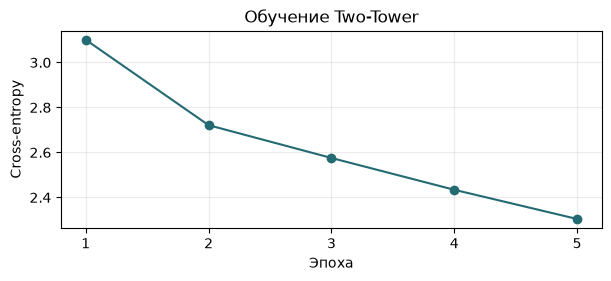

In [11]:
with threadpool_limits(limits=2):
    base = BookRecommender(books, tags, book_tags, train, seed=SEED)
    features = FeatureStore(base, tags, book_tags)
    neural, losses = train_two_tower(base, features, train)
    system = HybridSystem(base, features, neural)

user_example = pd.DataFrame({
    "Оценок в train": features.user_count,
    "Средняя": features.user_sum / features.user_count,
    "Доля оценок ≥ 4": features.user_likes / features.user_count,
}, index=base.users)
print("Признаки читателей")
display(user_example.head().round(3))
print("Признаки книг (жанры показаны для примера)")
display(features.book_stats.join(features.genres[["fantasy", "romance", "mystery"]]).head().round(3))

fig, ax = plt.subplots(figsize=(6, 2.7), layout="constrained")
ax.plot(range(1, len(losses) + 1), losses, marker="o", color="#246a73")
ax.set(xlabel="Эпоха", ylabel="Cross-entropy", title="Обучение Two-Tower",
       xticks=range(1, len(losses) + 1))
ax.grid(alpha=0.25)
plt.show()

In [12]:
with threadpool_limits(limits=2):
    validation_cases, validation_size = build_cases(
        system, validation, per_segment=VALID_PER_SEGMENT, seed=SEED + 10
    )
    tuned_weights = tune_hybrid(system, validation_cases)

display(tuned_weights.round(4))

,,Popularity,Content-Based,Item-Based CF,SVD,Two-Tower,Штраф MMR,nDCG@10 val,ILD val
Модель,Сегмент,,,,,,,,
Гибрид,Новые,0.0375,0.0375,0.8875,0.0375,0.00,0.12,0.0007,0.7137
Гибрид + Two-Tower,Новые,0.0244,0.0244,0.5769,0.0244,0.35,0.12,0.0007,0.7433
Гибрид,Короткая история,0.0500,0.7000,0.1500,0.1000,0.00,0.12,0.1083,0.2728
Гибрид + Two-Tower,Короткая история,0.0325,0.4550,0.0975,0.0650,0.35,0.02,0.1254,0.2615
Гибрид,Активные,0.0375,0.8875,0.0375,0.0375,0.00,0.06,0.0986,0.2339
Гибрид + Two-Tower,Активные,0.0325,0.5525,0.0325,0.0325,0.35,0.02,0.1302,0.2378


,Доступно в validation,Взято в validation,Доступно в test,Взято в test
Новые,2561,200,2563,450
Короткая история,9271,200,14243,450
Активные,23279,200,24020,450


,Precision@10,Recall@10,nDCG@10,ILD,Покрытие каталога
Модель,,,,,
Гибрид + Two-Tower,0.02830,0.12730,0.09138,0.42328,0.4377
Гибрид,0.02244,0.09984,0.07626,0.41705,0.4177
Content-Based,0.02259,0.09924,0.07485,0.38171,0.4150
Two-Tower,0.02274,0.10055,0.06670,0.43542,0.4356
Item-Based CF,0.00185,0.00928,0.00465,0.68649,0.1544
Popularity,0.00096,0.00203,0.00152,0.62945,0.0011
SVD,0.00081,0.00196,0.00151,0.67805,0.0017


Читатели  Precision@10  Recall@10  \
Сегмент          Модель                                                  
Новые            Popularity               450       0.00200    0.00106   
                 Content-Based            450       0.00200    0.00106   
                 Item-Based CF            450       0.00200    0.00108   
                 SVD                      450       0.00156    0.00084   
                 Two-Tower                450       0.00067    0.00213   
                 Гибрид                   450       0.00133    0.00066   
                 Гибрид + Two-Tower       450       0.00133    0.00066   
Короткая история Popularity               450       0.00044    0.00444   
                 Content-Based            450       0.01556    0.15556   
                 Item-Based CF            450       0.00222    0.02222   
                 SVD                      450       0.00044    0.00444   
                 Two-Tower                450       0.01556    0.15556   
                 Гибрид                   450       0.01578    0.15778   
                 Гибрид + Two-Tower       450       0.02000    0.20000   
Активные         Popularity               450       0.00044    0.00059   
                 Content-Based            450       0.05022    0.14110   
                 Item-Based CF            450       0.00133    0.00454   
                 SVD                      450       0.00044    0.00059   
                 Two-Tower                450       0.05200    0.14397   
                 Гибрид                   450       0.05022    0.14110   
                 Гибрид + Two-Tower       450       0.06356    0.18124   

                                     nDCG@10      ILD  
Сегмент          Модель                                
Новые            Popularity          0.00222  0.62936  
                 Content-Based       0.00222  0.62936  
                 Item-Based CF       0.00210  0.68383  
                 SVD                 0.00202  0.67825  
                 Two-Tower           0.00126  0.68648  
                 Гибрид              0.00186  0.71374  
                 Гибрид + Two-Tower  0.00184  0.74329  
Короткая история Popularity          0.00149  0.62948  
                 Content-Based       0.10631  0.28517  
                 Item-Based CF       0.00936  0.66165  
                 SVD                 0.00163  0.67826  
                 Two-Tower           0.08725  0.30293  
                 Гибрид              0.11101  0.30301  
                 Гибрид + Two-Tower  0.12634  0.29080  
Активные         Popularity          0.00085  0.62951  
                 Content-Based       0.11602  0.23059  
                 Item-Based CF       0.00249  0.71400  
                 SVD                 0.00088  0.67766  
                 Two-Tower           0.11160  0.31685  
                 Гибрид              0.11591  0.23441  
                 Гибрид + Two-Tower  0.14596  0.23574

Recall до переранжирования


,Пул 4 моделей,Пул + Two-Tower
Сегмент,,
Новые,0.02399,0.04490
Короткая история,0.36000,0.46889
Активные,0.39987,0.52546


Влияние MMR при фиксированных весах


Без MMR             С MMR         
                    nDCG@10      ILD  nDCG@10      ILD
Модель                                                
Гибрид              0.07645  0.39963  0.07626  0.41705
Гибрид + Two-Tower  0.09136  0.40169  0.09138  0.42328

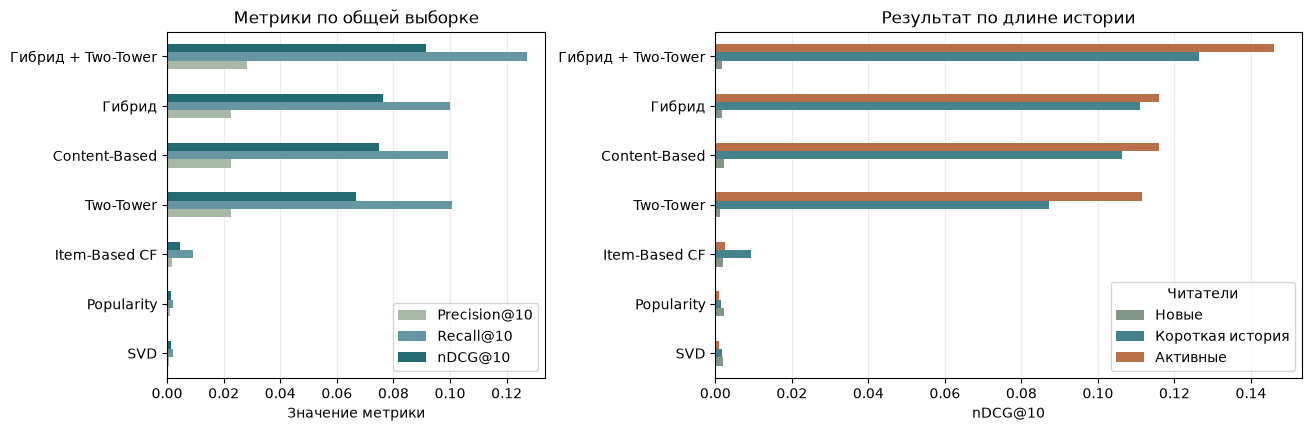

In [13]:
with threadpool_limits(limits=2):
    test_cases, test_size = build_cases(
        system, test, per_segment=TEST_PER_SEGMENT, seed=SEED + 20
    )
    by_segment, overall, pool_results = evaluate_system(system, test_cases)
    _, no_mmr, _ = evaluate_system(system, test_cases, use_mmr=False)

sample_sizes = pd.DataFrame({
    "Доступно в validation": validation_size,
    "Взято в validation": {name: len(cases) for name, cases in validation_cases.items()},
    "Доступно в test": test_size,
    "Взято в test": {name: len(cases) for name, cases in test_cases.items()},
})
display(sample_sizes)
display(overall.round(5))
display(by_segment.set_index(["Сегмент", "Модель"]).round(5))
print("Recall до переранжирования")
display(pool_results.set_index("Сегмент").round(5))

metric = f"nDCG@{K}"
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), layout="constrained",
                         gridspec_kw={"width_ratios": [1, 1.55]})
comparison = pd.concat({
    "Без MMR": no_mmr.loc[list(HYBRIDS), [metric, "ILD"]],
    "С MMR": overall.loc[list(HYBRIDS), [metric, "ILD"]],
}, axis=1)
print("Влияние MMR при фиксированных весах")
display(comparison.round(5))

overall.iloc[::-1][[f"Precision@{K}", f"Recall@{K}", metric]].plot.barh(
    ax=axes[0], color=["#a9b9a7", "#6696a1", "#246a73"]
)
axes[0].set(title="Метрики по общей выборке", xlabel="Значение метрики", ylabel="")
axes[0].legend(loc="lower right")
segment_ndcg = by_segment.pivot(index="Модель", columns="Сегмент", values=metric)
segment_ndcg.reindex(index=overall.index[::-1], columns=SEGMENTS).plot.barh(
    ax=axes[1], color=["#839788", "#45828d", "#b96f49"]
)
axes[1].set(title="Результат по длине истории", xlabel=metric, ylabel="")
axes[1].legend(title="Читатели", loc="lower right")
for ax in axes:
    ax.grid(axis="x", alpha=0.25)
    ax.set_axisbelow(True)
plt.show()

## 7. Примеры выдачи

Один и тот же вызов работает для известного читателя и читателя без единой оценки в train. В примере дополнительно проверяем, что в выдаче нет дублей и уже оценённых книг.

In [14]:
for segment in ("Активные", "Новые"):
    if not test_cases[segment]:
        continue
    user = test_cases[segment][0].user_id
    history_size = system.history_size(user)
    recommendation = system.get_recommendations(user, n=5)
    position = base.users.get_indexer([user])[0]
    seen, _ = base._history(position)
    assert recommendation.index.is_unique
    assert not recommendation.index.isin(base.books.index[seen]).any()
    print(f"Читатель {user} · {segment_name(history_size)} · оценок в train {history_size}")
    display(recommendation)

Читатель 35081 · Активные · оценок в train 22


,Место,title,authors
book_id,,,
4024,1,"The Program (The Program, #1)",Suzanne Young
1767,2,The Sky Is Everywhere,Jandy Nelson
324,3,Fangirl,Rainbow Rowell
1453,4,"Everything, Everything","Nicola Yoon, David Yoon"
2838,5,Love Letters to the Dead,Ava Dellaira


Читатель 43299 · Новые · оценок в train 0


,Место,title,authors
book_id,,,
5580,1,The Calvin and Hobbes Lazy Sunday Book,Bill Watterson
4778,2,The Holy Bible: English Standard Version,Anonymous
3275,3,"Harry Potter Boxed Set, Books 1-5 (Harry Potte...","J.K. Rowling, Mary GrandPré"
1308,4,A Court of Mist and Fury (A Court of Thorns an...,Sarah J. Maas
7883,5,The Sandman: King of Dreams,"Alisa Kwitney, Neil Gaiman"


## 8. Что получилось

Лучше всего у меня сработал **гибрид с Two-Tower**. На общей выборке получилось **0,02830 по Precision@10**, **0,12730 по Recall@10** и **0,09138 по nDCG@10**. Для сравнения, у классического гибрида nDCG был 0,07626, а у лучшей отдельной модели, Content-Based, — 0,07485. То есть добавление сети дало примерно 20% прироста к nDCG классического гибрида на этой выборке.

По группам видно что прибавка получилась разная.

- **Короткая история.** nDCG вырос с **0,11101** до **0,12634**. Даже если у читателя всего несколько оценок, по названиям и тегам уже можно найти похожие книги. Two-Tower добавила книги, которых не было в классическом пуле. Доля найденных релевантных книг в пуле выросла с 0,36000 до 0,46889.
- **Активные читатели.** Тут разница самая заметная. nDCG поднялся с **0,11591** до **0,14596**, а Recall пула — с 0,39987 до 0,52546. Сама Two-Tower набрала 0,11160 по nDCG. Получается, что в этом сегменте сеть лучше сработала в связке с контентной моделью.
- **Новые читатели.** У гибрида с Two-Tower вышло **0,00184** по nDCG, у Popularity — **0,00222**. В пуле релевантных книг стало больше (Recall вырос с 0,02399 до 0,04490), но до первой десятки они всё равно доходили редко. Пока истории нет, все новые читатели получают одинаковый список. Я бы для начала показал популярные книги и предложил выбрать несколько знакомых. По этому выбору уже можно собрать первый профиль.

Со штрафом MMR выдача стала разнообразнее. При тех же весах ILD у гибрида с Two-Tower вырос с **0,40169** до **0,42328**. По nDCG разницы почти нет — 0,09136 без штрафа и 0,09138 с ним. У классического гибрида разнообразие тоже выросло, а nDCG немного просел с 0,07645 до 0,07626. Всего гибрид с Two-Tower показал в рекомендациях 4 377 разных книг из 10 000.

| Подход | Что заметил в этом прогоне |
|---|---|
| Popularity | Удобно показывать новым читателям. Когда оценки уже есть, общий список мало учитывает вкусы конкретного человека. |
| Content-Based | Лучше всех отдельных моделей по nDCG. Хорошо находит книги из той же серии, но из-за этого в выдаче бывает слишком много похожего. |
| Item-Based CF | Можно показать, из-за какой похожей книги появилась рекомендация. Если оценок у читателя мало, подходящих соседей тоже мало и модель чаще опирается на средние оценки. |
| SVD | Быстро предсказывает оценки, но топ-10 у неё редко совпадали с тем, что читатели высоко оценили в тесте. |
| Two-Tower | Добавляет релевантные книги в пул, особенно для активных читателей. У новых читателей на входе одинаковые данные, а среди случайных негативов при обучении иногда могут оказаться книги, которые читателю бы понравились. |
| Гибриды | Можно смешивать кандидатов из разных источников и убирать из топа слишком похожие книги. Для другого каталога веса придётся заново подбирать. |

Думаю что здесь важно помнить про случайное разбиение и готовые теги Goodreads. Если появятся даты оценок, я бы повторил эксперимент с разбиением по времени. Для новых читателей ещё интересно сравнить, что получится, если попросить выбрать одну, три или пять знакомых книг.